# Data overview

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

repo_root = Path.cwd()
while not (repo_root / "src" / "processing").is_dir() and repo_root != repo_root.parent:
    repo_root = repo_root.parent

if not (repo_root / "src" / "processing").is_dir():
    raise RuntimeError("Buka notebook dari dalam folder repo.")

sys.path.insert(0, str(repo_root))

train_raw = pd.read_csv(repo_root / "data" / "train.csv", dtype={"id": str})
test_raw = pd.read_csv(repo_root / "data" / "test.csv", dtype={"id": str})

raw_frames = {"train.csv": train_raw, "test.csv": test_raw}
display(pd.DataFrame([
    {"file": name, "baris": len(frame), "kolom": frame.shape[1]}
    for name, frame in raw_frames.items()
]))

display(train_raw.head(3))

features = test_raw.columns.drop("id")
display(pd.DataFrame({
    "tipe train": train_raw[features].dtypes.astype(str),
    "nilai unik train": train_raw[features].nunique(),
    "NaN train": train_raw[features].isna().sum(),
    "NaN test": test_raw[features].isna().sum(),
}))

,file,baris,kolom
0,train.csv,27373,19
1,test.csv,6844,18


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1


,tipe train,nilai unik train,NaN train,NaN test
num_adults,float64,5,809,180
num_children,float64,6,3035,747
weekend_nights,int64,8,0,0
weekday_nights,int64,18,0,0
meal_package,str,4,1760,442
needs_parking,float64,2,1082,247
room_category,str,7,1002,242
days_before_arrival,float64,407,1123,290
arrival_year,int64,2,0,0
arrival_month,int64,12,0,0


# Split data dan fungsi untuk melihat tiap tahap

In [2]:
from src.processing.cleaning import cleaning, split_data

X_train, X_val, y_train, y_val, X_test, id_test = split_data(train_raw, test_raw)

splits = {"train": X_train, "validasi": X_val, "test": X_test}
stage_reports = {}


def show_stage(stage, frames):
    summary = pd.DataFrame([
        {
            "tahap": stage,
            "split": split,
            "baris": len(frame),
            "fitur": frame.shape[1],
            "numerik": frame.select_dtypes(include="number").shape[1],
            "NaN": int(frame.isna().sum().sum()),
        }
        for split, frame in frames.items()
    ])
    stage_reports[stage] = summary
    display(summary)
    display(frames["train"].head(3))


show_stage("Setelah split", splits)

duplicates_removed = len(train_raw) - len(X_train) - len(X_val)
print("Duplikat train yang dibuang saat split:", duplicates_removed)

,tahap,split,baris,fitur,numerik,NaN
0,Setelah split,train,21857,17,14,10643
1,Setelah split,validasi,5475,17,14,2675
2,Setelah split,test,6844,17,14,3281


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
3315,2.0,0.0,2,0,Half Board,0.0,Type B,388.0,2024,10,22,Offline Agent,0,0,0,NaN,1.0
9891,2.0,0.0,1,2,Breakfast,0.0,Type B,306.0,2024,11,3,Online Travel Agent,0,0,0,1501000.0,NaN
11242,1.0,0.0,0,2,Breakfast,0.0,Type B,166.0,2023,10,2,Offline Agent,0,0,0,1620000.0,0.0


Duplikat train yang dibuang saat split: 41


# Cleaning dan NaN sebelum–sesudah

In [3]:
X_train_clean, cleaner = cleaning(splits["train"], fit=True, name="train")

cleaned = {
    "train": X_train_clean,
    "validasi": cleaning(splits["validasi"], cleaner=cleaner, name="validasi")[0],
    "test": cleaning(splits["test"], cleaner=cleaner, name="test")[0],
}

show_stage("Setelah cleaning", cleaned)

missing = pd.DataFrame({
    "sebelum": splits["train"].isna().sum(),
    "sesudah": cleaned["train"].isna().sum(),
})
display(missing.sort_values("sebelum", ascending=False))

log = cleaner.report()
display(
    log.loc[log["n_rows"] > 0]
    .sort_values("n_rows", ascending=False)
    .head(12)
)

,tahap,split,baris,fitur,numerik,NaN
0,Setelah cleaning,train,21857,17,14,0
1,Setelah cleaning,validasi,5475,17,14,0
2,Setelah cleaning,test,6844,17,14,0


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
3315,2,0,2,0,Half Board,0,Type B,388,2024,10,22,Offline Agent,0,0,0,1631500.0,1
9891,2,0,1,2,Breakfast,0,Type B,306,2024,11,3,Online Travel Agent,0,0,0,1501000.0,0
11242,1,0,0,2,Breakfast,0,Type B,166,2023,10,2,Offline Agent,0,0,0,1620000.0,0


,sebelum,sesudah
num_children,2426,0
special_requests,2015,0
nightly_rate_idr,1593,0
meal_package,1403,0
needs_parking,885,0
days_before_arrival,875,0
room_category,810,0
num_adults,636,0
weekend_nights,0,0
arrival_year,0,0


,data,step,rule,col,n_rows
57,train,5,NaN diisi modus,num_children,2426
58,train,5,NaN diisi modus,special_requests,2015
52,train,5,NaN diisi median kamar di bulan x,nightly_rate_idr,1511
60,train,5,NaN diisi modus,meal_package,1403
59,train,5,NaN diisi modus,needs_parking,885
71,train,5,NaN diisi median,days_before_arrival,875
61,train,5,NaN diisi modus,room_category,810
203,test,5,NaN diisi modus,num_children,747
56,train,5,NaN diisi modus,num_adults,636
130,validasi,5,NaN diisi modus,num_children,609


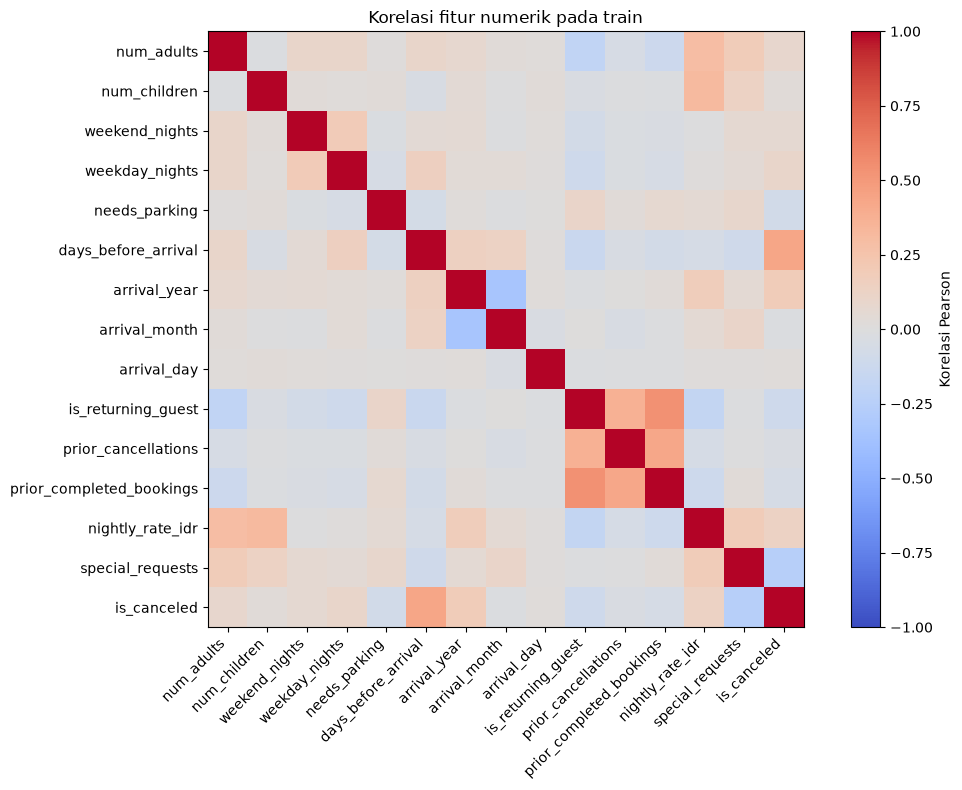

,Korelasi dengan is_canceled
days_before_arrival,0.4314
special_requests,-0.2511
arrival_year,0.1833
nightly_rate_idr,0.1300
is_returning_guest,-0.1066
weekday_nights,0.0970
needs_parking,-0.0836
num_adults,0.0807
prior_completed_bookings,-0.0584
weekend_nights,0.0576


In [7]:
analysis_train = cleaned["train"].assign(is_canceled=y_train)

corr = analysis_train.select_dtypes(include="number").corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 8))
heatmap = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ticks = range(len(corr))
ax.set_xticks(ticks, labels=corr.columns, rotation=45, ha="right")
ax.set_yticks(ticks, labels=corr.index)
ax.set_title("Korelasi fitur numerik pada train")
fig.colorbar(heatmap, ax=ax, label="Korelasi Pearson")
fig.tight_layout()
plt.show()

target_corr = (
    corr["is_canceled"]
    .drop("is_canceled")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
display(target_corr.to_frame("Korelasi dengan is_canceled").round(4))

In [8]:
overall_rate = analysis_train["is_canceled"].mean() * 100
print(f"Persentase batal seluruh train = {overall_rate:.2f}%")

for col in ["meal_package", "room_category", "booking_channel"]:
    rates = (
        analysis_train.groupby(col, observed=True)["is_canceled"]
        .agg(jumlah_booking="size", persen_batal="mean")
        .assign(persen_batal=lambda table: table["persen_batal"] * 100)
        .sort_values("persen_batal", ascending=False)
    )

    print(f"\n{col}")
    display(rates.round(2))

Persentase batal seluruh train = 32.76%

meal_package


,jumlah_booking,persen_batal
meal_package,,
Half Board,1786,45.41
Room Only,2925,33.68
Breakfast,17142,31.29
Full Board,4,25.00



room_category


,jumlah_booking,persen_batal
room_category,,
Type A,556,42.27
Type G,3555,33.45
Type B,17077,32.44
Type D,421,31.83
Type C,151,27.15
Type F,92,22.83
Type E,5,20.00



booking_channel


,jumlah_booking,persen_batal
booking_channel,,
Online Travel Agent,13989,36.41
Airline,72,31.94
Offline Agent,6351,29.95
Corporate,1203,11.89
Complimentary,242,0.00


# Encoding dan scaling

,tahap,split,baris,fitur,numerik,NaN
0,Setelah encoding,train,21857,30,30,0
1,Setelah encoding,validasi,5475,30,30,0
2,Setelah encoding,test,6844,30,30,0


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,...,room_category_Type C,room_category_Type D,room_category_Type E,room_category_Type F,room_category_Type G,booking_channel_Airline,booking_channel_Complimentary,booking_channel_Corporate,booking_channel_Offline Agent,booking_channel_Online Travel Agent
3315,2,0,2,0,0,388,2024,10,22,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9891,2,0,1,2,0,306,2024,11,3,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
11242,1,0,0,2,0,166,2023,10,2,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


,meal_package,meal_package_Breakfast,meal_package_Full Board,meal_package_Half Board,meal_package_Room Only
3315,Half Board,0.0,0.0,1.0,0.0
9891,Breakfast,1.0,0.0,0.0,0.0
11242,Breakfast,1.0,0.0,0.0,0.0
41,Breakfast,1.0,0.0,0.0,0.0
11576,Breakfast,1.0,0.0,0.0,0.0


,tahap,split,baris,fitur,numerik,NaN
0,Setelah scaling,train,21857,30,30,0
1,Setelah scaling,validasi,5475,30,30,0
2,Setelah scaling,test,6844,30,30,0


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,...,room_category_Type C,room_category_Type D,room_category_Type E,room_category_Type F,room_category_Type G,booking_channel_Airline,booking_channel_Complimentary,booking_channel_Corporate,booking_channel_Offline Agent,booking_channel_Online Travel Agent
3315,0.289245,-0.257754,1.350065,-1.547426,0,3.609958,0.468938,0.846479,0.736386,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9891,0.289245,-0.257754,0.207481,-0.139492,0,2.636628,0.468938,1.171459,-1.429566,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
11242,-1.665619,-0.257754,-0.935103,-0.139492,0,0.974845,-2.132478,0.846479,-1.543563,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


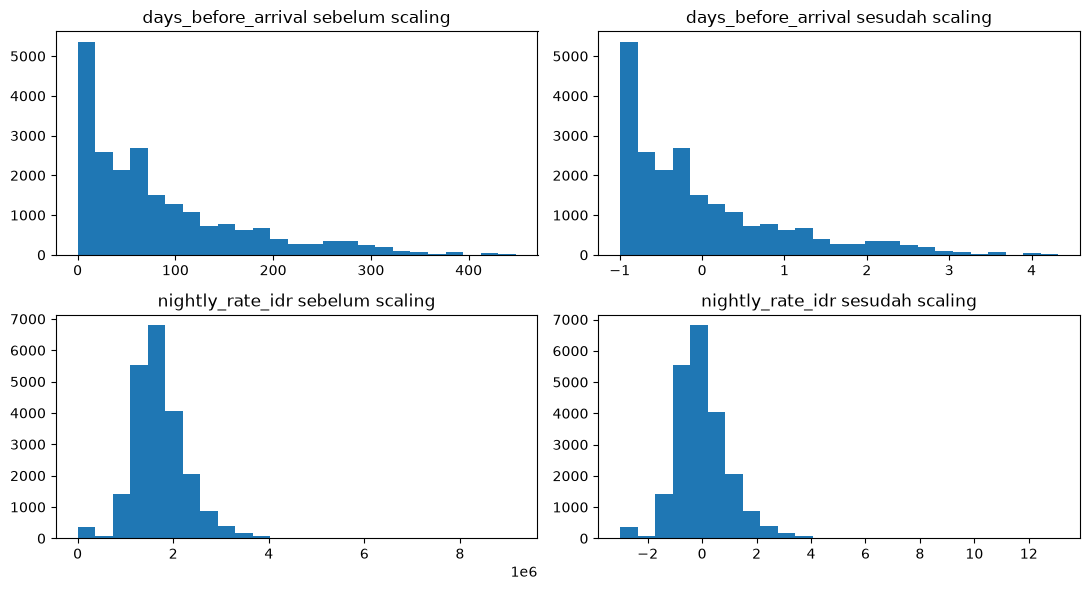

In [4]:
from src.processing.transformation import transformation
from src.processing.transformation.encoding import encode_features

X_train_scaled, transformer = transformation(cleaned["train"], fit=True)

encoder = transformer["encoder"]
cat_cols = encoder.feature_names_in_.tolist()

encoded = {
    split: encode_features(frame, encoder, cat_cols)
    for split, frame in cleaned.items()
}
show_stage("Setelah encoding", encoded)

meal_cols = [
    col for col in encoded["train"].columns
    if col.startswith("meal_package_")
]
display(cleaned["train"][["meal_package"]].join(encoded["train"][meal_cols]).head())

scaled = {
    "train": X_train_scaled,
    "validasi": transformation(cleaned["validasi"], transformer=transformer)[0],
    "test": transformation(cleaned["test"], transformer=transformer)[0],
}
show_stage("Setelah scaling", scaled)

plot_cols = ["days_before_arrival", "nightly_rate_idr"]
fig, axes = plt.subplots(len(plot_cols), 2, figsize=(11, 6))

for row, col in enumerate(plot_cols):
    axes[row, 0].hist(encoded["train"][col], bins=25)
    axes[row, 0].set_title(f"{col} sebelum scaling")
    axes[row, 1].hist(scaled["train"][col], bins=25)
    axes[row, 1].set_title(f"{col} sesudah scaling")

fig.tight_layout()
plt.show()

# Feature selection dan PCA

,tahap,split,baris,fitur,numerik,NaN
0,Setelah seleksi fitur,train,21857,15,15,0
1,Setelah seleksi fitur,validasi,5475,15,15,0
2,Setelah seleksi fitur,test,6844,15,15,0


,days_before_arrival,meal_package_Full Board,special_requests,arrival_year,is_returning_guest,needs_parking,booking_channel_Complimentary,room_category_Type E,room_category_Type A,room_category_Type C,booking_channel_Airline,booking_channel_Corporate,room_category_Type F,room_category_Type D,meal_package_Breakfast
3315,3.609958,0.0,0.498661,0.468938,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9891,2.636628,0.0,-0.774317,0.468938,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
11242,0.974845,0.0,-0.774317,-2.132478,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


,fitur_terpilih
0,days_before_arrival
1,meal_package_Full Board
2,special_requests
3,arrival_year
4,is_returning_guest
5,needs_parking
6,booking_channel_Complimentary
7,room_category_Type E
8,room_category_Type A
9,room_category_Type C


,tahap,split,baris,fitur,numerik,NaN
0,Setelah PCA,train,21857,2,2,0
1,Setelah PCA,validasi,5475,2,2,0
2,Setelah PCA,test,6844,2,2,0


,PC1,PC2
3315,-2.848048,0.249943
9891,-2.471773,-0.692314
11242,0.328473,-1.905424


,proporsi variansi,proporsi kumulatif
PC1,0.3459,0.3459
PC2,0.3133,0.6592


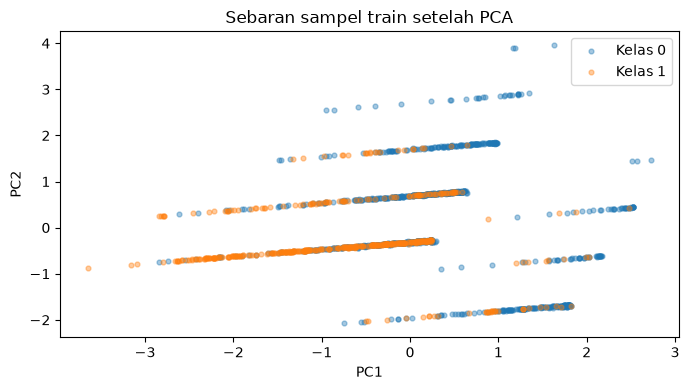

In [5]:
from src.processing.dimensionality_reduction import dimensionality_reduction
from src.processing.feature_selection import featureSelection

FEATURE_COUNT = 15
PCA_COMPONENTS = 2

if FEATURE_COUNT is None:
    selected_cols = scaled["train"].columns.tolist()
else:
    _, selected_cols = featureSelection(scaled["train"], y_train, FEATURE_COUNT)

selected = {
    split: frame.loc[:, selected_cols]
    for split, frame in scaled.items()
}

show_stage("Setelah seleksi fitur", selected)
display(pd.DataFrame({"fitur_terpilih": selected_cols}))

if PCA_COMPONENTS is None:
    reduced = selected
else:
    X_train_pca, reducer = dimensionality_reduction(
        selected["train"], fit=True, nComponents=PCA_COMPONENTS
    )
    reduced = {
        "train": X_train_pca,
        "validasi": dimensionality_reduction(selected["validasi"], reducer=reducer)[0],
        "test": dimensionality_reduction(selected["test"], reducer=reducer)[0],
    }

    show_stage("Setelah PCA", reduced)

    variance = pd.Series(reducer["explainedRatio"], index=X_train_pca.columns)
    display(pd.DataFrame({
        "proporsi variansi": variance,
        "proporsi kumulatif": variance.cumsum(),
    }).round(4))

    if X_train_pca.shape[1] >= 2:
        sample = X_train_pca.join(y_train.rename("is_canceled")).sample(
            n=min(1500, len(X_train_pca)), random_state=42
        )
        fig, ax = plt.subplots(figsize=(7, 4))

        for label, group in sample.groupby("is_canceled"):
            ax.scatter(
                group["PC1"], group["PC2"], s=12, alpha=0.4,
                label=f"Kelas {label}",
            )

        ax.set(xlabel="PC1", ylabel="PC2", title="Sebaran sampel train setelah PCA")
        ax.legend()
        fig.tight_layout()
        plt.show()